# Chapter 7: Support Vector Machines and Kernel Methods

This notebook covers Chapter 7 of *scikit-learn Cookbook* (3rd Edition, Packt). **Support Vector Machines (SVMs)** are powerful models for classification and regression. They find the boundary that separates classes with the **widest possible margin**, and with **kernels** they can learn complex, nonlinear boundaries.

**Topics covered:**
- Linear SVM classification and the maximum margin
- Support vectors and the `C` parameter (soft margin)
- The kernel trick: linear, polynomial, and RBF kernels
- The `gamma` parameter of the RBF kernel
- Why scaling matters for SVMs
- Hyperparameter tuning with `GridSearchCV`
- Support Vector Regression (SVR)
- `LinearSVC` for larger datasets

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import make_blobs, make_moons, load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.svm import SVC, SVR, LinearSVC
from sklearn.metrics import mean_squared_error, r2_score


def plot_svm(model, X, y, ax, title):
    """Plot the decision boundary, margins, and support vectors of a 2D SVM."""
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0, alpha=0.2, cmap='coolwarm')
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], linestyles=['--', '-', '--'], colors='k')
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=20)
    svm = model[-1] if hasattr(model, 'steps') else model
    if hasattr(svm, 'support_vectors_') and not hasattr(model, 'steps'):
        ax.scatter(svm.support_vectors_[:, 0], svm.support_vectors_[:, 1],
                   s=100, facecolors='none', edgecolors='k')
    ax.set_title(title)

## 1. Linear SVM and the Maximum Margin

Many lines can separate two classes. An SVM chooses the one with the **largest margin**: the widest gap between the boundary and the closest points of each class. The boundary is

$$\mathbf{w}^T\mathbf{x} + b = 0$$

and the margin width is $\frac{2}{\|\mathbf{w}\|}$, so maximizing the margin means minimizing $\|\mathbf{w}\|$.

The points that lie on or inside the margin are called **support vectors**. Only they determine the boundary: moving any other point (without crossing the margin) does not change the model.

Number of support vectors per class: [1 1]


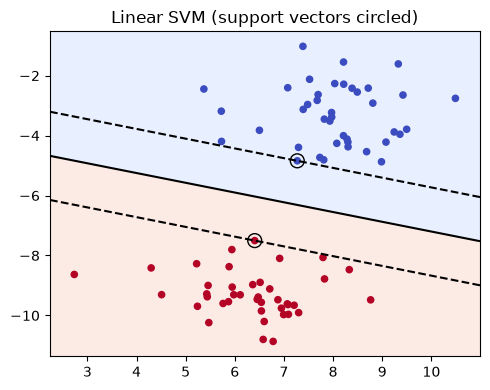

In [2]:
X_lin, y_lin = make_blobs(n_samples=80, centers=2, cluster_std=1.0, random_state=6)

svm_linear = SVC(kernel='linear', C=1.0).fit(X_lin, y_lin)
print('Number of support vectors per class:', svm_linear.n_support_)

fig, ax = plt.subplots(figsize=(5, 4))
plot_svm(svm_linear, X_lin, y_lin, ax, 'Linear SVM (support vectors circled)')
plt.tight_layout()
plt.show()

The solid line is the decision boundary and the dashed lines mark the margin. Only a few circled points (the support vectors) touch the margin, and they alone define where the boundary lies.

## 2. Soft Margin and the `C` Parameter

Real data is rarely perfectly separable, so SVMs allow some points to violate the margin (**soft margin**). The parameter `C` controls the trade-off:

$$\min_{\mathbf{w}, b} \frac{1}{2}\|\mathbf{w}\|^2 + C \sum_i \xi_i$$

where $\xi_i$ measures how much point $i$ violates the margin.
- **Small `C`**: wide margin, many violations allowed, smoother model (more regularization).
- **Large `C`**: narrow margin, few violations allowed, fits the training data closely (risk of overfitting).

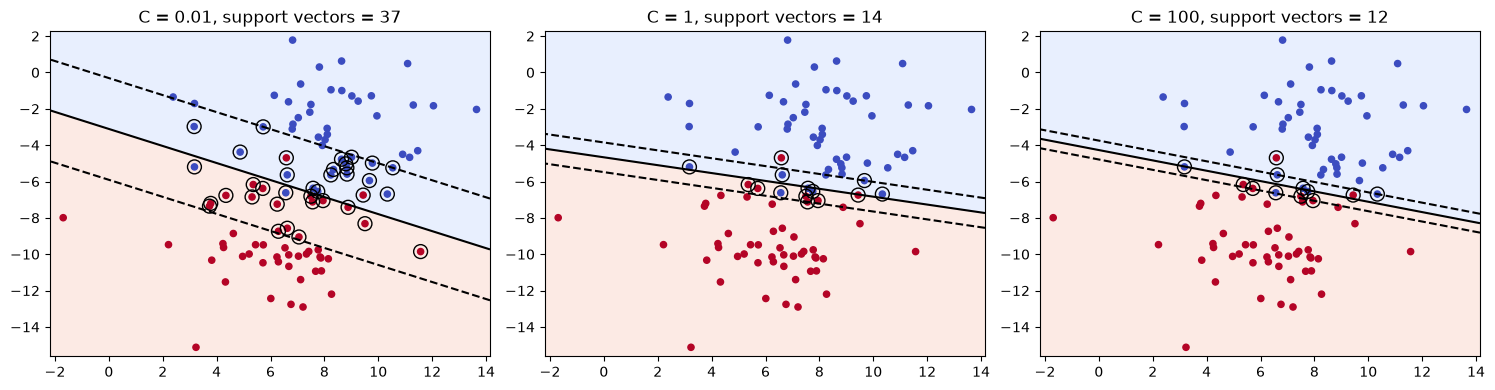

In [3]:
X_ov, y_ov = make_blobs(n_samples=100, centers=2, cluster_std=2.2, random_state=6)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, C in zip(axes, [0.01, 1, 100]):
    m = SVC(kernel='linear', C=C).fit(X_ov, y_ov)
    plot_svm(m, X_ov, y_ov, ax, f'C = {C}, support vectors = {m.n_support_.sum()}')
plt.tight_layout()
plt.show()

With a small `C`, the margin is wide and many points become support vectors. As `C` increases, the margin narrows and fewer points are allowed inside it, so the model follows the training data more closely.

## 3. The Kernel Trick

When classes cannot be separated by a straight line, SVMs use a **kernel**. A kernel computes the similarity between two points as if they were mapped into a higher-dimensional space where a linear boundary works, without ever computing that mapping explicitly (the **kernel trick**). Common kernels:
- **Linear**: $K(\mathbf{x}, \mathbf{z}) = \mathbf{x}^T\mathbf{z}$
- **Polynomial**: $K(\mathbf{x}, \mathbf{z}) = (\gamma\,\mathbf{x}^T\mathbf{z} + r)^d$
- **RBF (Gaussian)**: $K(\mathbf{x}, \mathbf{z}) = \exp(-\gamma \|\mathbf{x} - \mathbf{z}\|^2)$, the most popular default

The example uses the **moons** dataset, two interleaving half circles.

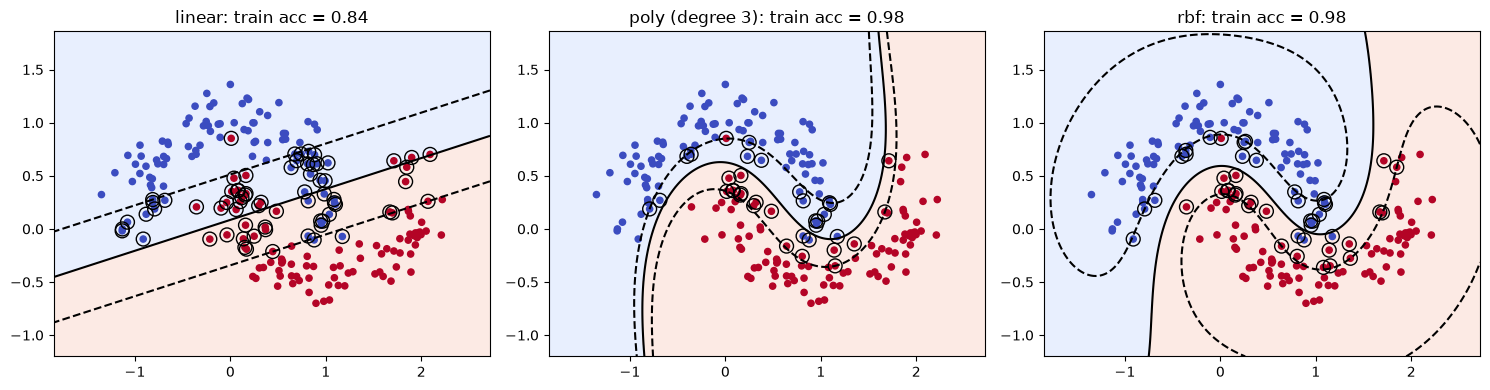

In [4]:
X_moon, y_moon = make_moons(n_samples=200, noise=0.15, random_state=42)

kernels = [('linear', SVC(kernel='linear', C=1)),
           ('poly (degree 3)', SVC(kernel='poly', degree=3, C=1, coef0=1)),
           ('rbf', SVC(kernel='rbf', C=1, gamma='scale'))]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, m) in zip(axes, kernels):
    m.fit(X_moon, y_moon)
    plot_svm(m, X_moon, y_moon, ax, f'{name}: train acc = {m.score(X_moon, y_moon):.2f}')
plt.tight_layout()
plt.show()

The linear kernel can only draw a straight line, so it misclassifies parts of both moons. The polynomial and RBF kernels bend the boundary to follow the curved shapes and reach much higher accuracy.

## 4. The `gamma` Parameter of the RBF Kernel

`gamma` controls how far the influence of a single training point reaches:
- **Small `gamma`**: each point influences a wide area, giving a smooth, simple boundary (risk of underfitting).
- **Large `gamma`**: each point influences only its close neighborhood, giving a very wiggly boundary that can wrap around individual points (risk of overfitting).

`gamma` and `C` interact, so they are usually tuned together.

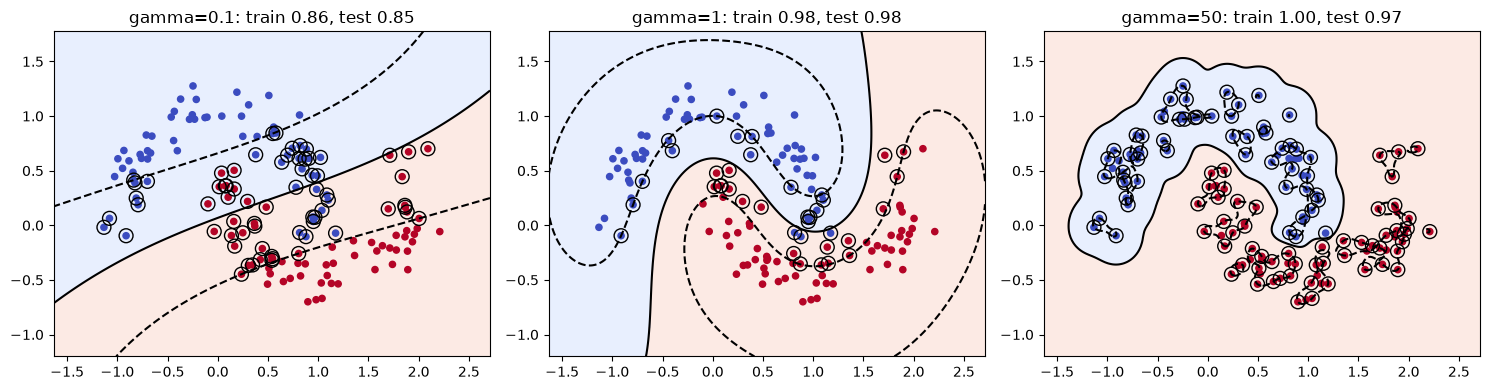

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X_moon, y_moon, test_size=0.3, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, gamma in zip(axes, [0.1, 1, 50]):
    m = SVC(kernel='rbf', C=1, gamma=gamma).fit(X_tr, y_tr)
    plot_svm(m, X_tr, y_tr, ax,
             f'gamma={gamma}: train {m.score(X_tr, y_tr):.2f}, test {m.score(X_te, y_te):.2f}')
plt.tight_layout()
plt.show()

A small `gamma` gives an almost linear boundary that underfits. A very large `gamma` creates small islands around individual training points: training accuracy is very high, but test accuracy drops, which is overfitting. A moderate value generalizes best.

## 5. Why Scaling Matters for SVMs

SVMs rely on distances (RBF kernel) and dot products (linear kernel), so features with larger ranges dominate. Scaling is essentially required. The **breast cancer** dataset, with features on very different scales, shows the effect.

In [6]:
cancer = load_breast_cancer()
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(cancer.data, cancer.target, test_size=0.25,
                                              random_state=42, stratify=cancer.target)

raw = SVC(kernel='rbf').fit(Xc_tr, yc_tr)
scaled = make_pipeline(StandardScaler(), SVC(kernel='rbf')).fit(Xc_tr, yc_tr)

print(f'RBF SVM without scaling: test accuracy = {raw.score(Xc_te, yc_te):.3f}')
print(f'RBF SVM with scaling:    test accuracy = {scaled.score(Xc_te, yc_te):.3f}')

RBF SVM without scaling: test accuracy = 0.923
RBF SVM with scaling:    test accuracy = 0.979


Scaling improves the SVM's accuracy noticeably, because otherwise a few large-valued features dominate the distance calculations in the RBF kernel.

## 6. Hyperparameter Tuning with GridSearchCV

The kernel, `C`, and `gamma` are tuned together with cross-validation. Values of `C` and `gamma` are usually searched on a logarithmic scale.

In [7]:
pipe = Pipeline([('scaler', StandardScaler()), ('svc', SVC())])
param_grid = [
    {'svc__kernel': ['linear'], 'svc__C': [0.01, 0.1, 1, 10]},
    {'svc__kernel': ['rbf'], 'svc__C': [0.1, 1, 10, 100],
     'svc__gamma': [0.001, 0.01, 0.1, 1]},
]
grid = GridSearchCV(pipe, param_grid, cv=5, n_jobs=-1).fit(Xc_tr, yc_tr)

print('Best parameters:', grid.best_params_)
print(f'Best CV accuracy: {grid.best_score_:.3f}')
print(f'Test accuracy:    {grid.score(Xc_te, yc_te):.3f}')

results = pd.DataFrame(grid.cv_results_)
rbf = results[results['param_svc__kernel'] == 'rbf']
rbf.pivot_table(index='param_svc__C', columns='param_svc__gamma',
                values='mean_test_score').round(3)

Best parameters: {'svc__C': 0.01, 'svc__kernel': 'linear'}
Best CV accuracy: 0.977
Test accuracy:    0.958


param_svc__gamma,0.001,0.010,0.100,1.000
param_svc__C,,,,
0.1,0.709,0.944,0.941,0.627
1.0,0.946,0.972,0.946,0.631
10.0,0.977,0.962,0.941,0.631
100.0,0.969,0.962,0.944,0.631


The grid search compares linear and RBF kernels over a range of `C` and `gamma` values. The table shows the RBF results: accuracy is low when both `C` and `gamma` are very small (underfitting) and also drops when `gamma` is too large (overfitting), with the best region in between.

## 7. Support Vector Regression (SVR)

**SVR** applies the margin idea to regression. It fits a function that keeps as many points as possible inside a tube of width $\varepsilon$ around the prediction. Errors smaller than $\varepsilon$ are ignored, and only points outside the tube (the support vectors) affect the model. `C` and `gamma` play the same roles as in classification.

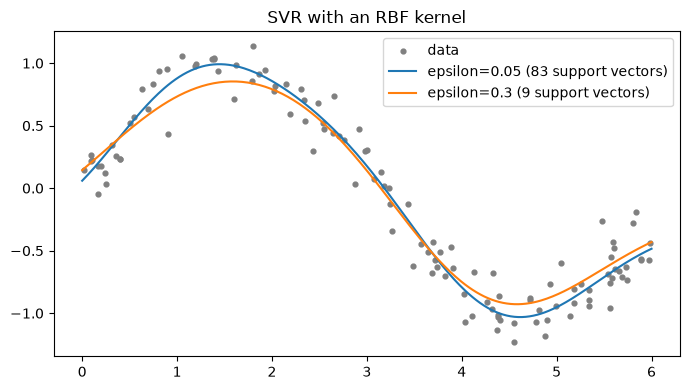

In [8]:
rng = np.random.default_rng(0)
X_s = np.sort(rng.uniform(0, 6, 120)).reshape(-1, 1)
y_s = np.sin(X_s).ravel() + rng.normal(0, 0.15, 120)

X_plot = np.linspace(0, 6, 300).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X_s, y_s, s=12, color='grey', label='data')
for eps in [0.05, 0.3]:
    svr = SVR(kernel='rbf', C=10, epsilon=eps).fit(X_s, y_s)
    ax.plot(X_plot, svr.predict(X_plot),
            label=f'epsilon={eps} ({len(svr.support_)} support vectors)')
ax.legend()
ax.set_title('SVR with an RBF kernel')
plt.tight_layout()
plt.show()

In [9]:
diab = load_diabetes()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(diab.data, diab.target,
                                              test_size=0.25, random_state=42)
svr = make_pipeline(StandardScaler(), SVR(kernel='rbf', C=100, epsilon=10))
svr.fit(Xd_tr, yd_tr)
pred = svr.predict(Xd_te)
print(f'SVR on diabetes: test RMSE = {mean_squared_error(yd_te, pred) ** 0.5:.2f}, '
      f'R2 = {r2_score(yd_te, pred):.3f}')

SVR on diabetes: test RMSE = 52.75, R2 = 0.497


SVR follows the sine-shaped pattern smoothly. A larger $\varepsilon$ creates a wider tube, so fewer points become support vectors and the model becomes simpler. On the diabetes data, SVR gives a reasonable regression model once the features are scaled.

## 8. LinearSVC for Larger Datasets

`SVC` with a kernel becomes slow as the number of samples grows (training time grows roughly between $O(n^2)$ and $O(n^3)$). When a linear boundary is enough, `LinearSVC` uses a specialized solver that scales much better.

In [10]:
X_big, y_big = make_blobs(n_samples=20000, centers=2, n_features=20,
                          cluster_std=4, random_state=0)

for name, m in [('SVC (linear kernel)', SVC(kernel='linear')),
                ('LinearSVC', LinearSVC())]:
    start = time.perf_counter()
    m.fit(X_big, y_big)
    print(f'{name:>20}: {time.perf_counter() - start:.2f} s, '
          f'train accuracy = {m.score(X_big, y_big):.3f}')

 SVC (linear kernel): 0.14 s, train accuracy = 1.000
           LinearSVC: 0.04 s, train accuracy = 1.000


Both models reach similar accuracy, but `LinearSVC` trains much faster. For large datasets with a linear structure (such as text classification), it is the practical choice.

## Chapter Summary

- SVMs find the decision boundary with the **maximum margin**, determined only by the **support vectors**.
- `C` controls the **soft margin**: small `C` gives a wider margin and smoother model, large `C` fits the training data more tightly.
- The **kernel trick** allows nonlinear boundaries: linear, polynomial, and **RBF** (the most common default).
- `gamma` controls the reach of each point in the RBF kernel: too small underfits, too large overfits.
- SVMs **require feature scaling**, and `C`, `gamma`, and the kernel should be tuned together with cross-validation.
- **SVR** extends SVMs to regression with an $\varepsilon$-insensitive tube.
- **LinearSVC** is much faster than kernel `SVC` on large datasets when a linear boundary is sufficient.